<a href="https://colab.research.google.com/github/nurfahdilla293/praktikum_evaluasi_model.ipynb/blob/main/Praktikum_8_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## Support Vector Machine (SVM): Hyperplane, Margin, dan Kernel Trick



In [ ]:
import numpy as np

w = np.array([2, 1])
b = -5
x_baru = np.array([4, 2])

norm_w = np.linalg.norm(w)          # ||w|| = sqrt(2^2 + 1^2)
margin = 2 / norm_w                 # lebar margin = 2 / ||w||
f_x = np.dot(w, x_baru) + b         # f(x) = w.x + b

print("||w||        =", round(norm_w, 3))
print("Lebar margin =", round(margin, 3))
print("f(4,2)       =", f_x)
print("Kelas        =", "POSITIF (di atas hyperplane)" if f_x > 0 else "NEGATIF (di bawah hyperplane)")

||w||        = 2.236
Lebar margin = 0.894
f(4,2)       = 5
Kelas        = POSITIF (di atas hyperplane)


**Interpretasi:**  
‖w‖ = √(2² + 1²) = √5 ≈ 2,236, sehingga lebar margin = 2 / 2,236 ≈ **0,894**.  
Untuk titik (4, 2): f(x) = (2·4) + (1·2) − 5 = **5**. Karena f(x) > 0, titik tersebut diklasifikasikan ke sisi **positif** hyperplane. Hasil perhitungan kode sama dengan perhitungan manual di materi.


### Praktikum 8.1 Persiapan Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

### Praktikum 8.2 Import Dataset

In [ ]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

print("Ukuran data  :", X.shape)
print("Nama kelas   :", list(data.target_names))
print("Distribusi y :\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("\nData latih:", X_train.shape, "| Data uji:", X_test.shape)

Ukuran data  : (569, 30)
Nama kelas   : [np.str_('malignant'), np.str_('benign')]
Distribusi y :
 target
1    357
0    212
Name: count, dtype: int64

Data latih: (455, 30) | Data uji: (114, 30)


### Praktikum 8.3 Preprocessing
SVM sensitif terhadap skala fitur, sehingga scaling (`StandardScaler`) wajib dilakukan. Scaler dimasukkan ke dalam `Pipeline` agar hanya di-fit pada data latih (mencegah data leakage saat cross-validation).

In [ ]:
pipeline = Pipeline([("scaler", StandardScaler()), ("svm", SVC())])
pipeline

Pipeline(steps=[('scaler', StandardScaler()), ('svm', SVC())])

### Praktikum 8.4 Training Model dengan GridSearchCV

In [ ]:
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1],
    "svm__kernel": ["rbf", "linear"]
}

grid_search = GridSearchCV(pipeline, param_grid, cv=5,
                           scoring="f1", n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Parameter terbaik:", grid_search.best_params_)
print("F1-Score terbaik (CV):", round(grid_search.best_score_, 3))

Parameter terbaik: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
F1-Score terbaik (CV): 0.984


### Praktikum 8.5 Evaluasi

In [ ]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print("Akurasi Test:", round(accuracy_score(y_test, y_pred), 3))
print()
print(classification_report(y_test, y_pred, target_names=data.target_names))

Akurasi Test: 0.982

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### Praktikum 8.6 Visualisasi (Heatmap hasil GridSearchCV, kernel RBF)

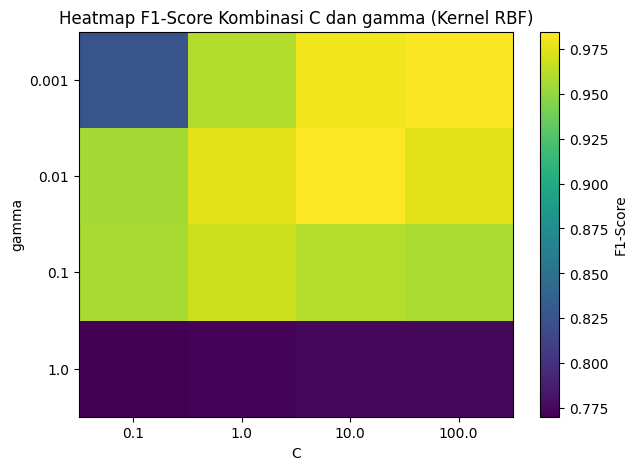

param_svm__C      0.1    1.0    10.0   100.0
param_svm__gamma                            
0.001             0.826  0.960  0.979  0.983
0.010             0.956  0.976  0.984  0.976
0.100             0.956  0.968  0.961  0.957
1.000             0.770  0.772  0.774  0.774


In [ ]:
import pandas as pd

hasil = pd.DataFrame(grid_search.cv_results_)
hasil_rbf = hasil[hasil["param_svm__kernel"] == "rbf"]      # heatmap hanya untuk kernel RBF
pivot = hasil_rbf.pivot_table(values="mean_test_score",
                              index="param_svm__gamma",
                              columns="param_svm__C")

plt.figure(figsize=(7, 5))
plt.imshow(pivot, cmap="viridis", aspect="auto")
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xlabel("C"); plt.ylabel("gamma")
plt.title("Heatmap F1-Score Kombinasi C dan gamma (Kernel RBF)")
plt.colorbar(label="F1-Score")
plt.show()

print(pivot.round(3))

**Interpretasi Heatmap:**  
Heatmap GridSearchCV membantu memvisualisasikan wilayah kombinasi C dan gamma yang menghasilkan performa terbaik. Umumnya, area "puncak" performa berada pada rentang tertentu nilai C dan gamma yang jauh lebih besar atau lebih kecil dari area tersebut menghasilkan performa yang menurun karena *overfitting* atau *underfitting*. Pada hasil di atas, kombinasi gamma yang terlalu besar (1) menurunkan F1-Score karena model terlalu mengikuti detail data latih (overfitting), sedangkan C yang terlalu kecil membuat margin terlalu lebar sehingga model kurang fleksibel (underfitting).

## 3. Praktikum 8.7: Perbandingan Kernel
Membandingkan kernel linear, polynomial, dan RBF pada dataset yang sama (`StandardScaler` + `SVC`).

In [ ]:
for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=kernel))])
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"Kernel {kernel}: akurasi = {acc:.3f}")

Kernel linear: akurasi = 0.974
Kernel poly: akurasi = 0.912
Kernel rbf: akurasi = 0.982


## 4. Latihan Praktikum 1: Perbandingan Kernel
**Tujuan:** Membandingkan performa kernel linear, polynomial, dan RBF pada dataset yang sama.

Di Praktikum 8.7 sudah dibandingkan lewat satu kali train/test split. Supaya perbandingan lebih adil dan tidak bergantung pada satu split, di sini ditambah **5-fold Stratified CV** (akurasi dan F1) serta tabel ringkasan.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import pandas as pd

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=kernel))])
    acc_cv = cross_val_score(model, X, y, cv=skf, scoring="accuracy")
    f1_cv  = cross_val_score(model, X, y, cv=skf, scoring="f1")
    model.fit(X_train, y_train)
    acc_test = accuracy_score(y_test, model.predict(X_test))
    rows.append({"Kernel": kernel,
                 "Akurasi Test": round(acc_test, 3),
                 "Akurasi CV (mean)": round(acc_cv.mean(), 3),
                 "F1 CV (mean)": round(f1_cv.mean(), 3),
                 "F1 CV (std)": round(f1_cv.std(), 3)})

tabel_kernel = pd.DataFrame(rows).set_index("Kernel")
tabel_kernel

,Akurasi Test,Akurasi CV (mean),F1 CV (mean),F1 CV (std)
Kernel,,,,
linear,0.974,0.974,0.979,0.017
poly,0.912,0.905,0.930,0.020
rbf,0.982,0.977,0.982,0.013


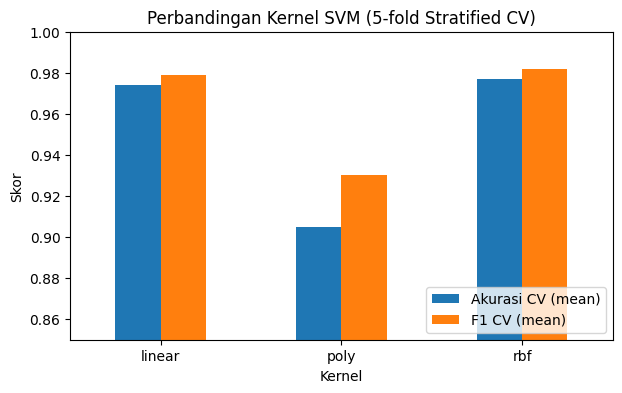

In [ ]:
tabel_kernel[["Akurasi CV (mean)", "F1 CV (mean)"]].plot(kind="bar", figsize=(7,4), rot=0)
plt.ylim(0.85, 1.0)
plt.title("Perbandingan Kernel SVM (5-fold Stratified CV)")
plt.ylabel("Skor")
plt.legend(loc="lower right")
plt.show()

**Analisis Latihan 1:**  
Dataset breast cancer memiliki 30 fitur dan kedua kelasnya hampir *linearly separable* setelah scaling. Karena itu kernel **linear** dan **RBF** menghasilkan performa yang sangat dekat dan tinggi, sedangkan kernel **polynomial** (derajat 3 default) cenderung lebih rendah (akurasi test 0,912 dibanding 0,974 untuk linear dan 0,982 untuk RBF) karena batas keputusannya terlalu kompleks untuk data yang sebenarnya sudah hampir terpisah linear. Sesuai tabel kapan digunakan di materi (8.4), kernel linear cocok untuk data yang (hampir) linearly separable, sedangkan RBF cocok untuk data non-linear kompleks. Dalam kasus ini tidak ada keuntungan besar memakai kernel yang lebih kompleks.

## 5. Latihan Praktikum 2: Visualisasi Decision Boundary 2 Fitur
**Tujuan:** Memvisualisasikan pengaruh kernel dan parameter C/gamma pada decision boundary.

**Instruksi:** Pilih 2 fitur dari dataset `load_breast_cancer`, latih SVM dengan beberapa kombinasi kernel/C/gamma, dan visualisasikan decision boundary masing-masing.

Fitur yang dipilih: **mean radius** dan **mean texture** (dua fitur yang mudah diinterpretasi dan menunjukkan pemisahan kelas yang cukup jelas).

In [ ]:
fitur = ["mean radius", "mean texture"]
X2 = X[fitur].values
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y.values, test_size=0.2, random_state=42, stratify=y)

scaler2 = StandardScaler().fit(X2_train)
X2_train_s = scaler2.transform(X2_train)
X2_test_s  = scaler2.transform(X2_test)

def plot_boundary(ax, model, Xs, ys, judul):
    x_min, x_max = Xs[:,0].min()-1, Xs[:,0].max()+1
    y_min, y_max = Xs[:,1].min()-1, Xs[:,1].max()+1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(Xs[:,0], Xs[:,1], c=ys, cmap="coolwarm", edgecolors="k", s=18)
    ax.scatter(model.support_vectors_[:,0], model.support_vectors_[:,1],
               s=90, facecolors="none", edgecolors="green", linewidths=1)
    ax.set_title(judul, fontsize=9)
    ax.set_xlabel(fitur[0]); ax.set_ylabel(fitur[1])

### 5a. Pengaruh Kernel (C = 1)

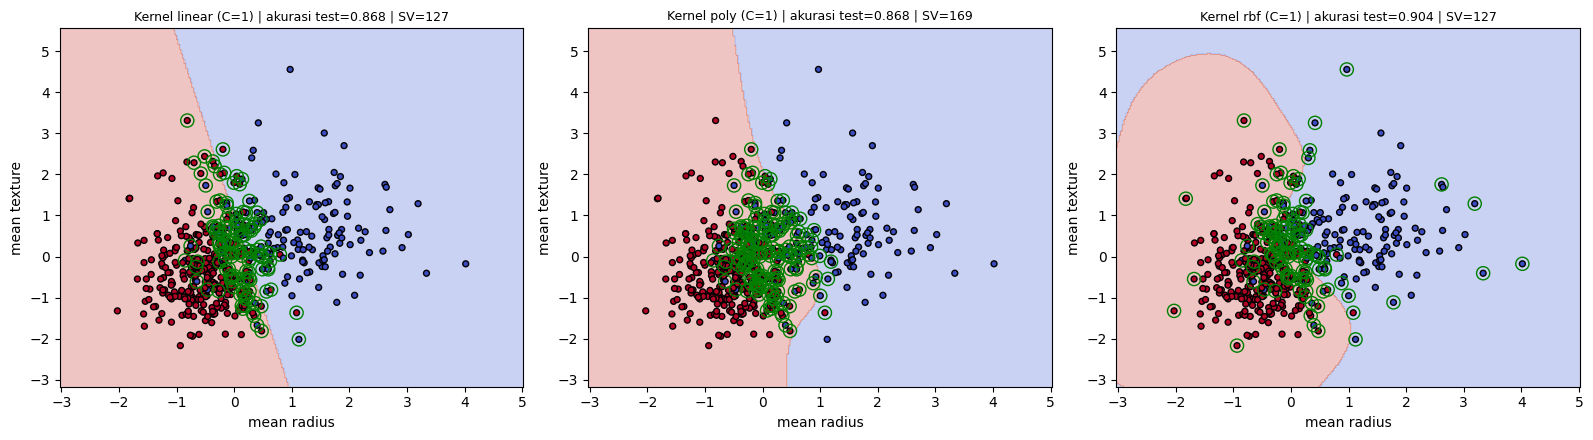

In [ ]:
konfigurasi_kernel = [("linear", {}), ("poly", {"degree": 3}), ("rbf", {"gamma": "scale"})]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (k, p) in zip(axes, konfigurasi_kernel):
    m = SVC(kernel=k, C=1, **p).fit(X2_train_s, y2_train)
    acc = accuracy_score(y2_test, m.predict(X2_test_s))
    plot_boundary(ax, m, X2_train_s, y2_train,
                  f"Kernel {k} (C=1) | akurasi test={acc:.3f} | SV={len(m.support_vectors_)}")
plt.tight_layout(); plt.show()

### 5b. Pengaruh Parameter C (kernel linear)

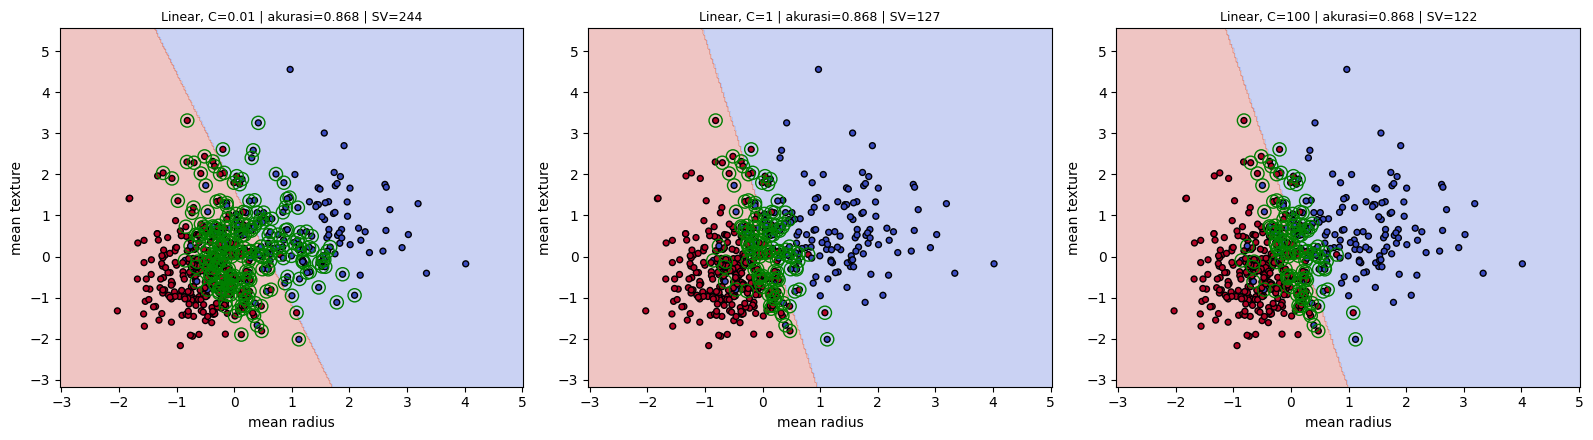

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, C_ in zip(axes, [0.01, 1, 100]):
    m = SVC(kernel="linear", C=C_).fit(X2_train_s, y2_train)
    acc = accuracy_score(y2_test, m.predict(X2_test_s))
    plot_boundary(ax, m, X2_train_s, y2_train,
                  f"Linear, C={C_} | akurasi={acc:.3f} | SV={len(m.support_vectors_)}")
plt.tight_layout(); plt.show()

### 5c. Pengaruh Parameter gamma (kernel RBF, C = 1)

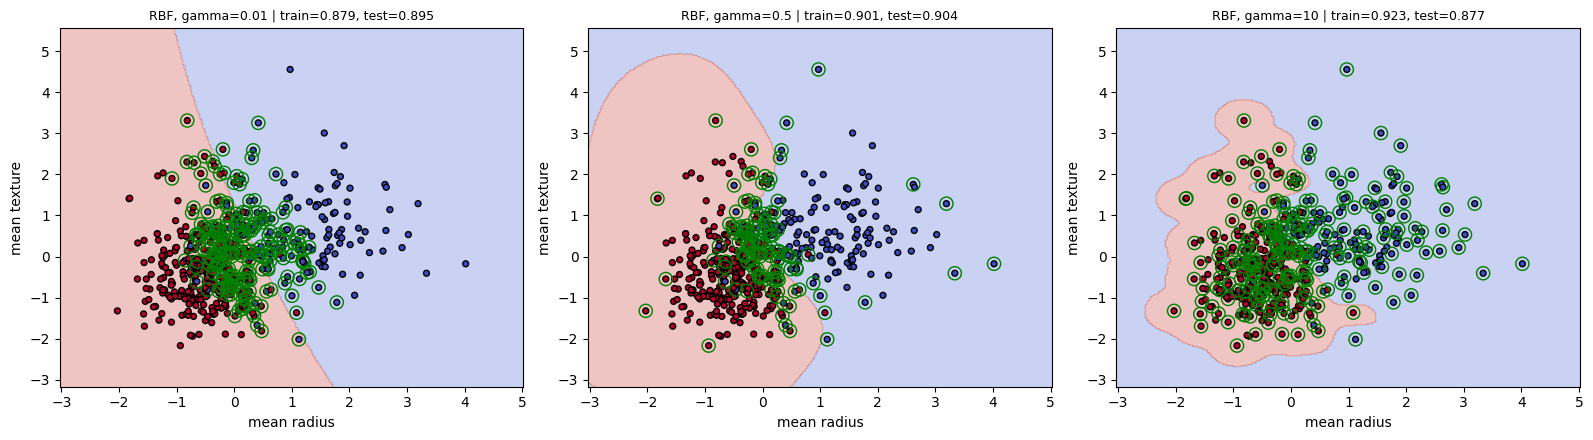

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, g in zip(axes, [0.01, 0.5, 10]):
    m = SVC(kernel="rbf", C=1, gamma=g).fit(X2_train_s, y2_train)
    acc_tr = accuracy_score(y2_train, m.predict(X2_train_s))
    acc_te = accuracy_score(y2_test, m.predict(X2_test_s))
    plot_boundary(ax, m, X2_train_s, y2_train,
                  f"RBF, gamma={g} | train={acc_tr:.3f}, test={acc_te:.3f}")
plt.tight_layout(); plt.show()

### 5d. Ringkasan Kombinasi (C dan gamma pada RBF)

In [ ]:
rows = []
for C_ in [0.1, 1, 100]:
    for g in [0.01, 0.5, 10]:
        m = SVC(kernel="rbf", C=C_, gamma=g).fit(X2_train_s, y2_train)
        rows.append({"C": C_, "gamma": g,
                     "Akurasi Train": round(accuracy_score(y2_train, m.predict(X2_train_s)), 3),
                     "Akurasi Test":  round(accuracy_score(y2_test,  m.predict(X2_test_s)), 3),
                     "Jumlah SV": len(m.support_vectors_)})
ringkasan = pd.DataFrame(rows)
ringkasan["Selisih (train-test)"] = (ringkasan["Akurasi Train"] - ringkasan["Akurasi Test"]).round(3)
ringkasan

,C,gamma,Akurasi Train,Akurasi Test,Jumlah SV,Selisih (train-test)
0,0.1,0.01,0.741,0.754,340,-0.013
1,0.1,0.50,0.912,0.904,200,0.008
2,0.1,10.00,0.851,0.851,369,0.000
3,1.0,0.01,0.879,0.895,211,-0.016
4,1.0,0.50,0.901,0.904,127,-0.003
5,1.0,10.00,0.923,0.877,249,0.046
6,100.0,0.01,0.903,0.895,118,0.008
7,100.0,0.50,0.908,0.886,106,0.022
8,100.0,10.00,0.958,0.860,195,0.098


**Analisis Latihan 2:**  
Kernel RBF paling fleksibel dan akurasinya sedikit lebih tinggi (0,904) dibanding linear dan polynomial (0,868), karena batasnya bisa mengikuti sebaran kelas yang tidak sepenuhnya lurus.
C kecil menghasilkan margin lebar dengan banyak support vector (244 SV pada C=0,01 vs 122 pada C=100), berisiko underfitting, sedangkan C besar membuat margin sempit dan berisiko overfitting.
Gamma besar (10) membuat batas bergerigi mengikuti titik data, sehingga akurasi train naik tetapi akurasi test turun, tanda overfitting.

## 6. Kesimpulan
SVM memisahkan kelas dengan hyperplane w·x + b = 0 yang memaksimalkan margin (2/‖w‖), dan pada dataset breast cancer pipeline dengan scaling dan GridSearchCV menghasilkan model RBF terbaik (C=10, gamma=0,01) dengan akurasi test 0,982, sementara kernel linear dan RBF sama-sama baik karena data hampir linearly separable. Parameter C mengatur trade-off margin dan kesalahan klasifikasi, sedangkan gamma mengatur jangkauan pengaruh tiap sampel, dan nilai yang terlalu ekstrem pada keduanya menyebabkan underfitting atau overfitting. Kekurangan SVM adalah pelatihannya lambat untuk data besar (O(n²)–O(n³)) dan tidak menghasilkan probabilitas secara langsung